In [22]:
from cfb.config import ROOT, SQL_ANALYSIS_DIR
from cfb.db import engine, read_query
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# modeling (scikit-learn)
import joblib                                                   # save / load the trained model
from sklearn.linear_model import LogisticRegression             # baseline model
from sklearn.ensemble import HistGradientBoostingClassifier     # main model: handles NULLs, monotonic constraints
from sklearn.pipeline import (make_pipeline, Pipeline)
from sklearn.impute import SimpleImputer                        # fill NULLs for the baseline (logistic can't take them)
from sklearn.preprocessing import (StandardScaler,SplineTransformer,OneHotEncoder)
from sklearn.isotonic import IsotonicRegression                 # calibrate probabilities on the validation season
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split,GridSearchCV,PredefinedSplit
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
)

import tensorflow as tf
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [21]:
def plot_history(history, title="Learning curves"):
    h = history.history
    epochs = np.arange(1, len(h["loss"]) + 1)
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    axes[0].plot(epochs, h["loss"], label="Training loss")
    axes[0].plot(epochs, h["val_loss"], label="Validation loss")
    axes[0].axvline(best_epoch, linestyle=":", color="gray",
                    label=f"Min val loss: {best_epoch}")
    axes[0].set_ylabel("BCE + any L2 penalty")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].plot(epochs, h["auc"], label="Training ROC AUC")
    axes[1].plot(epochs, h["val_auc"], label="Validation ROC AUC")
    axes[1].axvline(best_epoch, linestyle=":", color="gray")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("ROC AUC")
    axes[1].legend()
    axes[1].grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [23]:
go_query = '''
SELECT
    *,
    CASE WHEN outcome = 'converted' THEN 1 ELSE 0 END as CONVERT_TARGET
FROM marts.fourth_down_features
WHERE decision = 'go'
'''
df = pd.read_sql(go_query, engine)
go = df.copy()

In [24]:
go.head()

,play_id,game_id,drive_id,season,week,offense,defense,decision,distance,yards_to_goal,...,def_ppa_szn,off_elo,def_elo,elo_diff,offense_spread,fg_pct_szn,fg_att_szn,off_games_prior,outcome,convert_target
0,2124200083604,212420008,21242000836,2001,2,Arkansas,UNLV,go,5,43,...,NaN,1497.0,1501.0,-4.0,NaN,NaN,NaN,0.0,converted,1
1,2124200083608,212420008,21242000836,2001,2,Arkansas,UNLV,go,10,37,...,NaN,1497.0,1501.0,-4.0,NaN,NaN,NaN,0.0,converted,1
2,2124200213314,212420021,21242002133,2001,2,San Diego State,Arizona,go,4,38,...,NaN,1425.0,1558.0,-133.0,NaN,NaN,NaN,0.0,failed,0
3,2124202380701,212420238,21242023807,2001,2,Middle Tennessee,Vanderbilt,go,3,27,...,NaN,1513.0,1434.0,79.0,NaN,NaN,NaN,0.0,converted,1
4,2124400250604,212440025,21244002506,2001,2,Illinois,California,go,1,17,...,NaN,1533.0,1488.0,45.0,NaN,NaN,NaN,0.0,converted,1


Text(0.5, 1.0, 'Target Distribution (TO counts as Fail)')

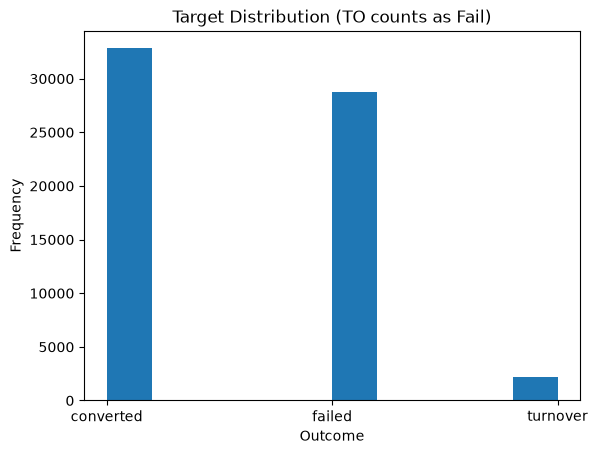

In [25]:
plt.hist(x=go['outcome'])
plt.xlabel('Outcome')
plt.ylabel('Frequency')
plt.title('Target Distribution (TO counts as Fail)')

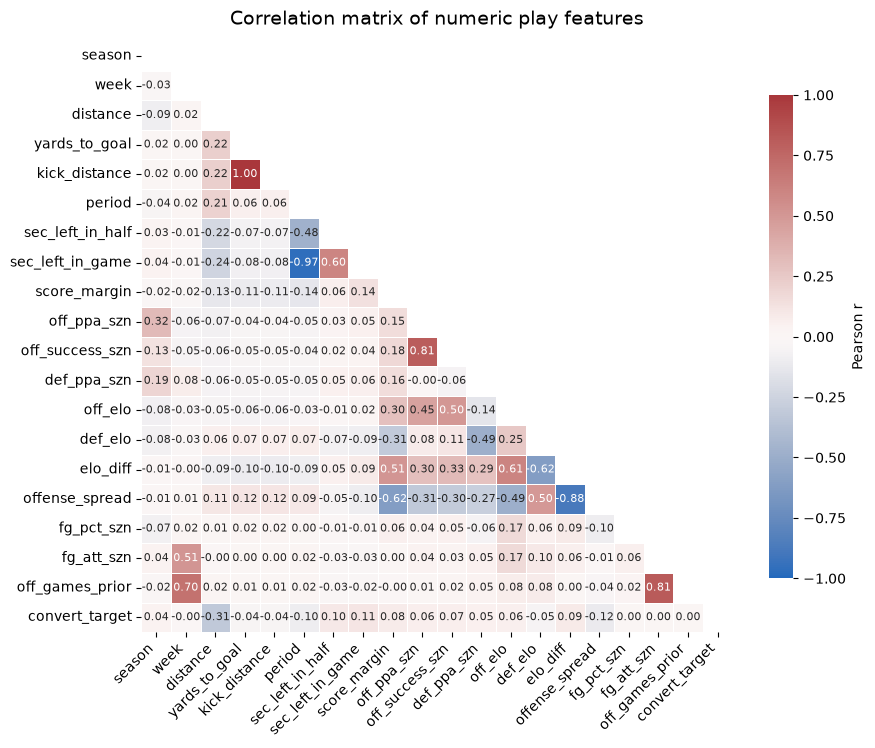

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Numeric columns, minus IDs and anything with no variance
num = (
    go.select_dtypes(include='number')
      .drop(columns=['play_id', 'game_id', 'drive_id', 'old_game_id'], errors='ignore')
)
num = num.loc[:, num.nunique(dropna=True) > 1]   # drop constant / all-NaN columns

corr = num.corr(method='pearson', min_periods=30)

# Mask the redundant upper triangle (and the diagonal)
mask = np.triu(np.ones_like(corr, dtype=bool))

n = len(corr)
fig, ax = plt.subplots(figsize=(max(8, n * 0.45), max(6, n * 0.4)))

sns.heatmap(
    corr,
    mask=mask,
    cmap='vlag',            # diverging: blue = negative, red = positive
    center=0, vmin=-1, vmax=1,
    square=True,
    linewidths=0.5, linecolor='white',
    annot=n <= 20,          # only annotate when it stays readable
    fmt='.2f', annot_kws={'size': 8},
    cbar_kws={'shrink': 0.7, 'label': 'Pearson r'},
    ax=ax,
)

ax.set_title('Correlation matrix of numeric play features', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
# Drop Identifiers and Descriptors
go = go.drop(columns=['play_id', 'game_id','drive_id','offense','defense','decision','outcome'], errors='ignore')

X = go.drop(columns='convert_target', errors='ignore')
y = go['convert_target']

preprocessor = make_pipeline(
    SimpleImputer(strategy='median', add_indicator=True),
    StandardScaler()
)

# Make splits before to maintain test integrity
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=1/9,
    random_state=42
)

# Scale the training data
X_train_scaled = preprocessor.fit_transform(X_train).astype('float32')
X_val_scaled = preprocessor.transform(X_val).astype('float32')
X_test_scaled = preprocessor.transform(X_test).astype('float32')

# Check the sets
print("Training:", X_train_scaled.shape, np.bincount(y_train))
print("Validation:", X_val_scaled.shape, np.bincount(y_val))
print("Test:", X_test_scaled.shape, np.bincount(y_test))
print("Convert proportion:", f"{y.mean():.1%}")
print("Input features:", X_train_scaled.shape[1])

Training: (50952, 36) [24737 26215]
Validation: (6369, 36) [3083 3286]
Test: (6370, 36) [3059 3311]
Convert proportion: 51.5%
Input features: 36


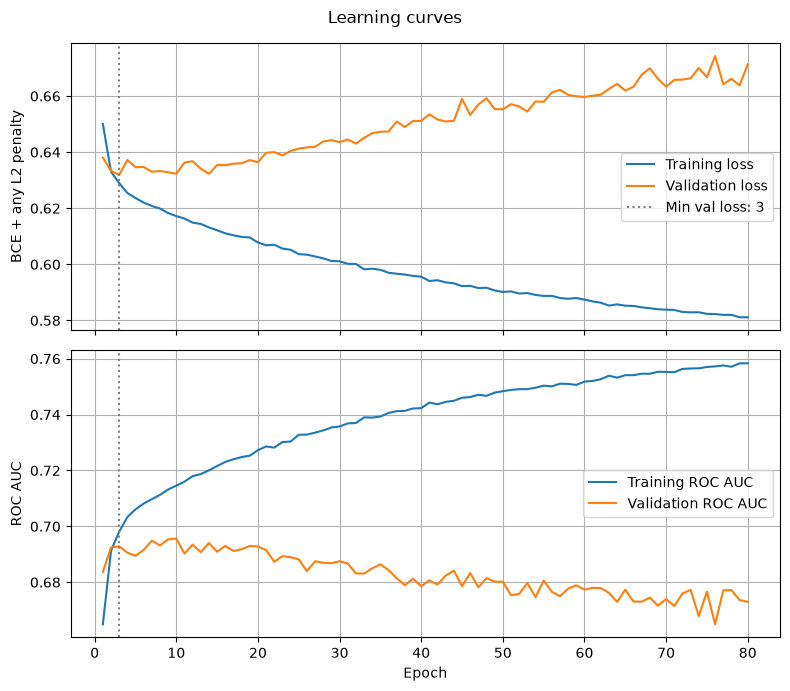

1593/1593 ━━━━━━━━━━━━━━━━━━━━ 1s 812us/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 829us/step
Training AUC Score      : 0.7673506705764941
Validation AUC Score    : 0.6730511636960703
Validation Accuracy     : 0.62443083686607


In [32]:
num_features = X_train_scaled.shape[1]

base_model = Sequential([
    Input(shape=(num_features,)), # Features in a 1D array
    Dense(64, activation='relu', kernel_initializer="he_normal"),
    Dense(32, activation='relu', kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid") # 1 output because its either converted or not
])

opt = Adam(learning_rate=0.001)

base_model.compile(loss='binary_crossentropy',
                    optimizer=opt,
                    metrics=['accuracy',tf.keras.metrics.AUC(name='auc')])

base_history = base_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled,y_val),
    epochs=80,
    batch_size=60,
    verbose=0
)

plot_history(base_history)

base_train_preds = base_model.predict(X_train_scaled).ravel()
base_val_preds = base_model.predict(X_val_scaled).ravel()

# AUC ROC Scores
base_train_roc = roc_auc_score(y_train, base_train_preds)
base_val_roc = roc_auc_score(y_val, base_val_preds)

# Accuracy Score
base_val_accuracy = accuracy_score(y_val, base_val_preds >= 0.5)

print(f"Training AUC Score      : {base_train_roc}")
print(f"Validation AUC Score    : {base_val_roc}")
print(f"Validation Accuracy     : {base_val_accuracy}")

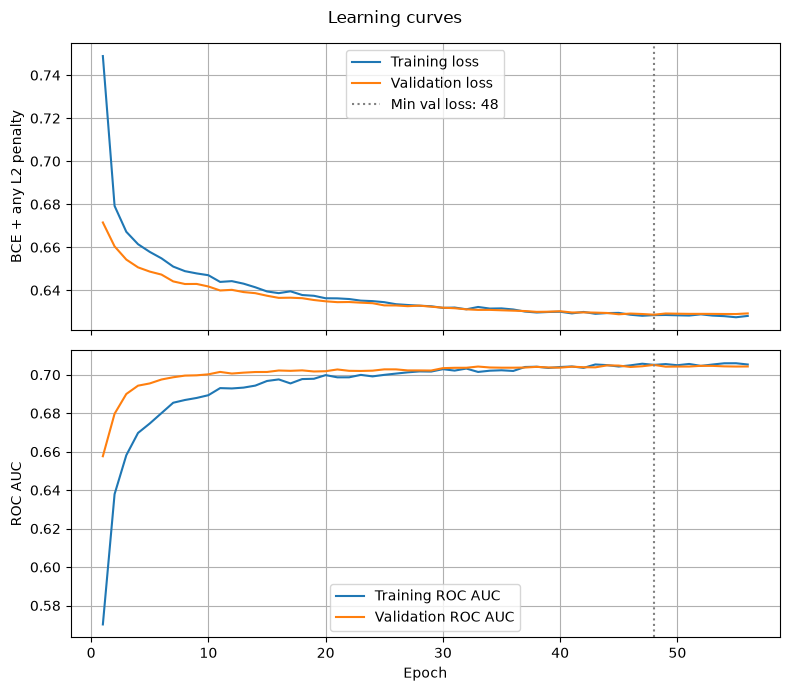

1593/1593 ━━━━━━━━━━━━━━━━━━━━ 1s 724us/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 762us/step
Training AUC Score      : 0.7139656005515231
Validation AUC Score    : 0.7050566306225667
Validation Accuracy     : 0.6511226252158895


In [38]:
# Early Stopping and Dropout

tf.keras.utils.set_random_seed(42)

# New Model
es_model = Sequential([
    Input(shape=(num_features,)),
    Dense(64, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(32, activation='relu', kernel_initializer='he_normal',
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),
])

es_opt = Adam(learning_rate=0.001)

es_model.compile(loss='binary_crossentropy',
                 optimizer=es_opt,
                 metrics=['accuracy',tf.keras.metrics.AUC(name='auc')]
)

# Add in Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

es_history = es_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)

# Evaluate
plot_history(es_history)

es_train_preds = es_model.predict(X_train_scaled).ravel()
es_val_preds = es_model.predict(X_val_scaled).ravel()

# AUC ROC Scores
es_train_roc = roc_auc_score(y_train, es_train_preds)
es_val_roc = roc_auc_score(y_val, es_val_preds)

# Accuracy Score
es_val_accuracy = accuracy_score(y_val, es_val_preds >= 0.5)

print(f"Training AUC Score      : {es_train_roc}")
print(f"Validation AUC Score    : {es_val_roc}")
print(f"Validation Accuracy     : {es_val_accuracy}")